In [1]:
import pandas as pd

In [3]:
cpi = pd.read_csv('CPILFESL.csv',
                  parse_dates=['observation_date'],
                  index_col='observation_date')

In [4]:
cpi.head()

,CPILFESL
observation_date,
1957-01-01,28.5
1957-02-01,28.6
1957-03-01,28.7
1957-04-01,28.8
1957-05-01,28.8


In [11]:
cpi = cpi.rename(columns={'CPILFESL':'cpi'})

In [13]:
cpi.describe()

,cpi
count,835.000000
mean,143.703056
std,90.000488
min,28.500000
25%,48.750000
50%,143.700000
75%,218.022500
max,337.765000


In [14]:
type(cpi.index)

pandas.core.indexes.datetimes.DatetimeIndex

In [16]:
cpi.index.is_unique

True

In [19]:
pd.infer_freq(cpi.index)

'MS'

In [20]:
cpi['cpi'].isna()

observation_date
1957-01-01    False
1957-02-01    False
1957-03-01    False
1957-04-01    False
1957-05-01    False
              ...  
2026-04-01    False
2026-05-01    False
2026-06-01    False
2026-07-01    False
2026-08-01    False
Name: cpi, Length: 836, dtype: bool

In [18]:
cpi.loc[cpi['cpi'].isna()]

,cpi
observation_date,
2025-10-01,NaN


In [21]:
cpi.loc['1982-01-01']

cpi    93.3
Name: 1982-01-01 00:00:00, dtype: float64

In [23]:
cpi.loc['1982-01-01':]

,cpi
observation_date,
1982-01-01,93.300
1982-02-01,93.800
1982-03-01,93.900
1982-04-01,94.700
1982-05-01,95.400
...,...
2026-04-01,335.423
2026-05-01,336.121
2026-06-01,336.065


In [24]:
cpi.loc['2020-01-01':'2021-01-01']

,cpi
observation_date,
2020-01-01,266.716
2020-02-01,267.370
2020-03-01,267.054
2020-04-01,265.746
2020-05-01,265.412
2020-06-01,265.849
2020-07-01,267.389
2020-08-01,268.422
2020-09-01,268.933


In [25]:
cpi.loc[cpi.index >= '2020-01-01']

,cpi
observation_date,
2020-01-01,266.716
2020-02-01,267.370
2020-03-01,267.054
2020-04-01,265.746
2020-05-01,265.412
...,...
2026-04-01,335.423
2026-05-01,336.121
2026-06-01,336.065


In [26]:
cpi.loc[(cpi.index >= '2020-01-01') & (cpi.cpi >= 300)]

,cpi
observation_date,
2022-11-01,300.325
2022-12-01,301.394
2023-01-01,302.642
2023-02-01,304.123
2023-03-01,305.147
2023-04-01,306.534
2023-05-01,307.652
2023-06-01,308.322
2023-07-01,308.960


In [28]:
cpi['previous_month'] = cpi['cpi'].shift(1)
cpi.tail()

,cpi,previous_month
observation_date,,
2026-04-01,335.423,334.165
2026-05-01,336.121,335.423
2026-06-01,336.065,336.121
2026-07-01,336.789,336.065
2026-08-01,337.765,336.789


In [31]:
cpi['diff'] = cpi['cpi'] - cpi['previous_month']
cpi.tail()

,cpi,previous_month,diff
observation_date,,,
2026-04-01,335.423,334.165,1.258
2026-05-01,336.121,335.423,0.698
2026-06-01,336.065,336.121,-0.056
2026-07-01,336.789,336.065,0.724
2026-08-01,337.765,336.789,0.976


In [44]:
cpi['monthly_change_pct'] = cpi['cpi'].pct_change(fill_method=None) * 100
cpi['year_over_year_pct'] = cpi['cpi'].pct_change(periods=12, fill_method=None) * 100
cpi.tail()

,cpi,previous_month,diff,monthly_change_pct,year_over_year_pct
observation_date,,,,,
2026-04-01,335.423,334.165,1.258,0.376461,2.743309
2026-05-01,336.121,335.423,0.698,0.208095,2.822942
2026-06-01,336.065,336.121,-0.056,-0.016661,2.565785
2026-07-01,336.789,336.065,0.724,0.215435,2.466518
2026-08-01,337.765,336.789,0.976,0.289796,2.446163


In [47]:
annual_cpi = cpi['cpi'].resample('YS').agg(['mean', 'min', 'max', 'count'])
annual_cpi['mean'].pct_change()
annual_cpi.tail()

,mean,min,max,count
observation_date,,,,
2022-01-01,294.306667,286.757,301.394,12
2023-01-01,308.378583,302.642,313.195,12
2024-01-01,318.989833,314.319,323.259,12
2025-01-01,328.042545,324.638,331.814,11
2026-01-01,335.329125,332.793,337.765,8


In [48]:
annual_cpi['annual_inflation'] = annual_cpi['mean'].pct_change()
annual_cpi.tail()

,mean,min,max,count,annual_inflation
observation_date,,,,,
2022-01-01,294.306667,286.757,301.394,12,0.061517
2023-01-01,308.378583,302.642,313.195,12,0.047814
2024-01-01,318.989833,314.319,323.259,12,0.034410
2025-01-01,328.042545,324.638,331.814,11,0.028379
2026-01-01,335.329125,332.793,337.765,8,0.022212


In [56]:
annual_cpi.loc[annual_cpi['annual_inflation'] == annual_cpi.annual_inflation.max()]

,mean,min,max,count,annual_inflation
observation_date,,,,,
1980-01-01,80.783333,76.7,84.9,12,0.124203


<Axes: xlabel='observation_date'>

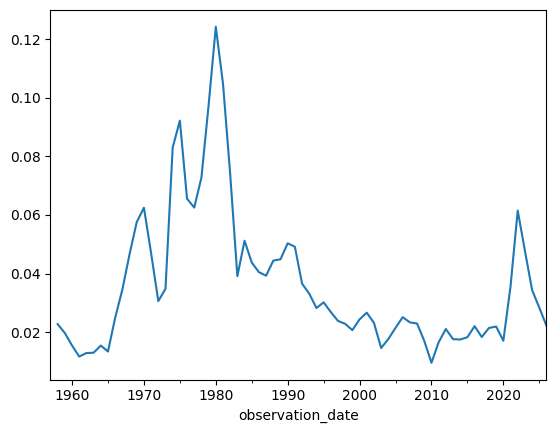

In [57]:
annual_cpi['annual_inflation'].plot.line()

<Axes: xlabel='observation_date'>

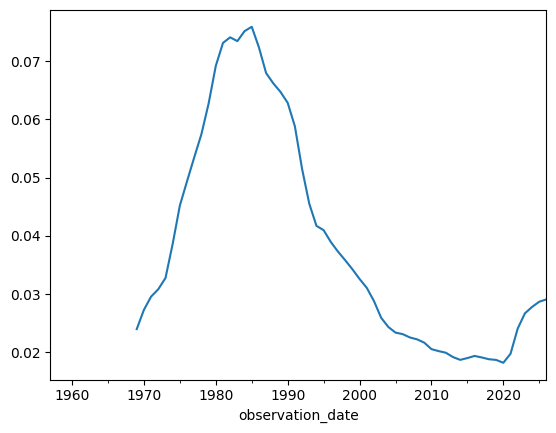

In [58]:
annual_cpi['annual_inflation'].rolling(window=12).mean().plot.line()